In [1]:
import os, random, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from scipy.signal import convolve2d

In [2]:
MODEL_PATH = "best_cifar10_model.keras"
LEGACY_MODEL_PATH = "best_cifar10_model.h5"
CNN_MODEL_PATH = "cnn_scratch_cifar10.keras"

if os.path.exists(MODEL_PATH):
    best_model = keras.models.load_model(MODEL_PATH)
    print(f"Loaded saved model from {MODEL_PATH}")
elif os.path.exists(LEGACY_MODEL_PATH):
    best_model = keras.models.load_model(LEGACY_MODEL_PATH)
    print(f"Loaded saved model from {LEGACY_MODEL_PATH}")
elif os.path.exists(CNN_MODEL_PATH):
    best_model = keras.models.load_model(CNN_MODEL_PATH)
    print(f"Loaded saved model from {CNN_MODEL_PATH}")
else:
    best_model = None
    print("No saved model found. Train and test the scratch CNN once to create one.")

No saved model found. Train and test the scratch CNN once to create one.


In [3]:
CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]
NUM_CLASSES = 10

(X_train_raw, y_train), (X_test_raw, y_test) = keras.datasets.cifar10.load_data()
print("X_train:", X_train_raw.shape, X_train_raw.dtype)
print("y_train:", y_train.shape, y_train.dtype)
print("X_test :", X_test_raw.shape, X_test_raw.dtype)
print("y_test :", y_test.shape, y_test.dtype)
print("Unique labels:", np.unique(y_train))
assert X_train_raw.shape == (50000, 32, 32, 3)
assert X_test_raw.shape == (10000, 32, 32, 3)
assert X_train_raw.dtype == np.uint8

X_train: (50000, 32, 32, 3) uint8
y_train: (50000, 1) uint8
X_test : (10000, 32, 32, 3) uint8
y_test : (10000, 1) uint8
Unique labels: [0 1 2 3 4 5 6 7 8 9]


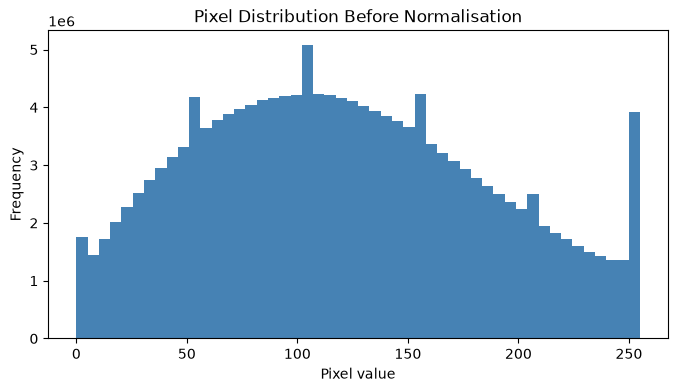

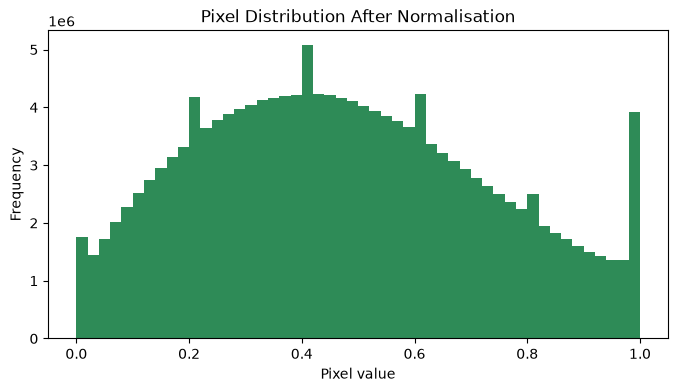

Normalised range: 0.0 to 1.0


In [4]:
plt.figure(figsize=(8, 4))
plt.hist(X_train_raw.flatten(), bins=50, color="steelblue")
plt.title("Pixel Distribution Before Normalisation")
plt.xlabel("Pixel value"); plt.ylabel("Frequency")
plt.show()

X_train = X_train_raw.astype("float32") / 255.0
X_test = X_test_raw.astype("float32") / 255.0

plt.figure(figsize=(8, 4))
plt.hist(X_train.flatten(), bins=50, color="seagreen")
plt.title("Pixel Distribution After Normalisation")
plt.xlabel("Pixel value"); plt.ylabel("Frequency")
plt.show()

print("Normalised range:", X_train.min(), "to", X_train.max())

In [5]:
y_train_ohe = keras.utils.to_categorical(y_train, NUM_CLASSES)
y_test_ohe = keras.utils.to_categorical(y_test, NUM_CLASSES)
print("One-hot training labels:", y_train_ohe.shape)
print("One-hot test labels:", y_test_ohe.shape)
assert y_train_ohe.shape == (50000, 10)

One-hot training labels: (50000, 10)
One-hot test labels: (10000, 10)


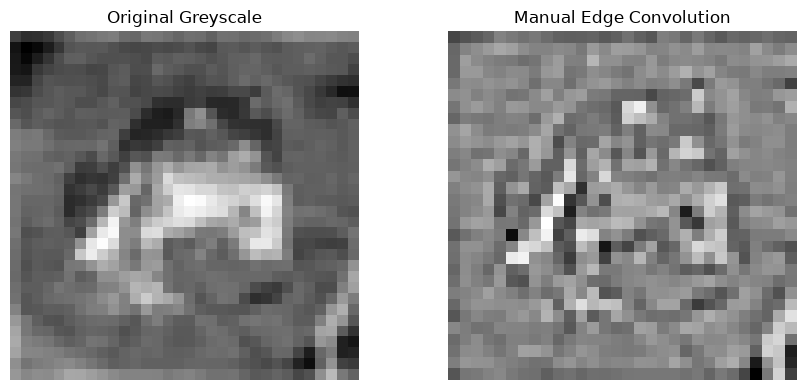

Input shape: (32, 32) Convolved shape: (30, 30)


In [6]:
gray = np.mean(X_train[0], axis=2)
edge_kernel = np.array([[-1, -1, -1],
                        [-1,  8, -1],
                        [-1, -1, -1]], dtype=np.float32)
conv_valid = convolve2d(gray, edge_kernel, mode="valid")

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(gray, cmap="gray"); ax[0].set_title("Original Greyscale")
ax[1].imshow(conv_valid, cmap="gray"); ax[1].set_title("Manual Edge Convolution")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()
print("Input shape:", gray.shape, "Convolved shape:", conv_valid.shape)

VALID output: (1, 30, 30, 8)
SAME output : (1, 32, 32, 8)


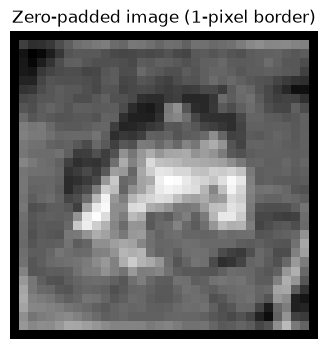

In [7]:
sample = X_train[:1]
valid_model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(8, 3, strides=1, padding="valid")
])
same_model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(8, 3, strides=1, padding="same")
])
print("VALID output:", valid_model(sample).shape)
print("SAME output :", same_model(sample).shape)

padded_gray = np.pad(gray, ((1, 1), (1, 1)), mode="constant")
plt.figure(figsize=(4, 4))
plt.imshow(padded_gray, cmap="gray")
plt.title("Zero-padded image (1-pixel border)")
plt.axis("off"); plt.show()

In [8]:
for stride in (1, 2):
    m = keras.Sequential([
        keras.Input(shape=(32, 32, 3)),
        layers.Conv2D(8, 3, strides=stride, padding="same")
    ])
    print(f"stride={stride} ->", m(sample).shape)

stride=1 -> (1, 32, 32, 8)
stride=2 -> (1, 16, 16, 8)


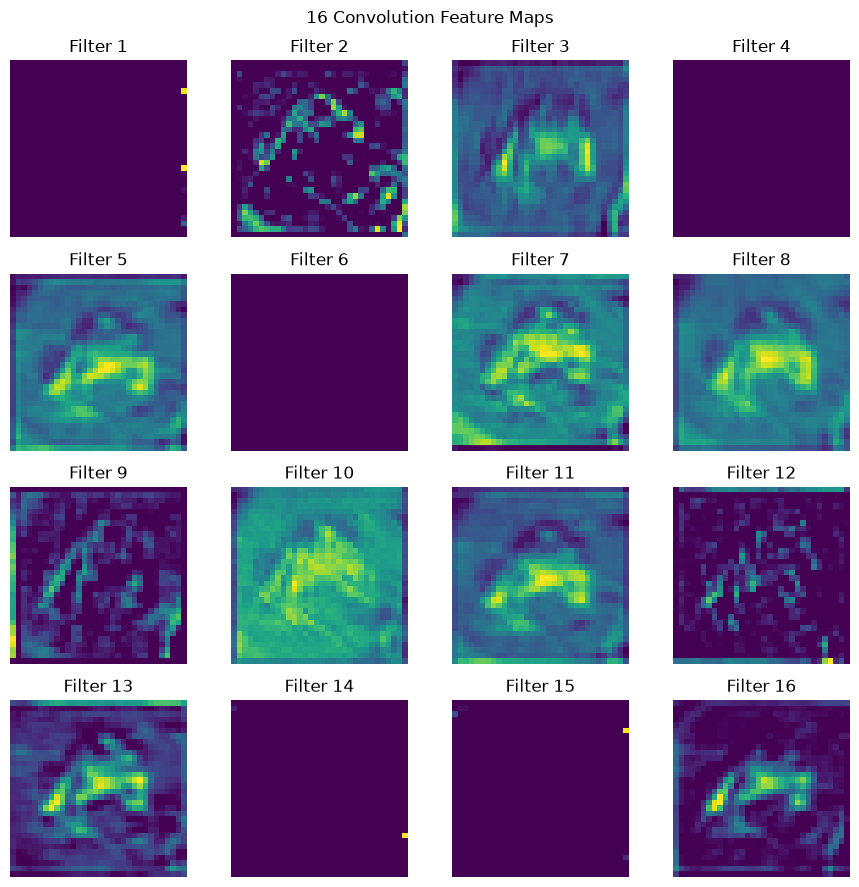

In [9]:
model_vis = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(16, (3, 3), activation="relu", padding="same")
])
feature_maps = model_vis.predict(sample, verbose=0)[0]
fig, axes = plt.subplots(4, 4, figsize=(9, 9))
for i, ax in enumerate(axes.flat):
    ax.imshow(feature_maps[:, :, i], cmap="viridis")
    ax.set_title(f"Filter {i+1}")
    ax.axis("off")
plt.suptitle("16 Convolution Feature Maps")
plt.tight_layout(); plt.show()

Before pooling: (32, 32, 16)
After max pooling: (16, 16, 16)
After average pooling: (16, 16, 16)


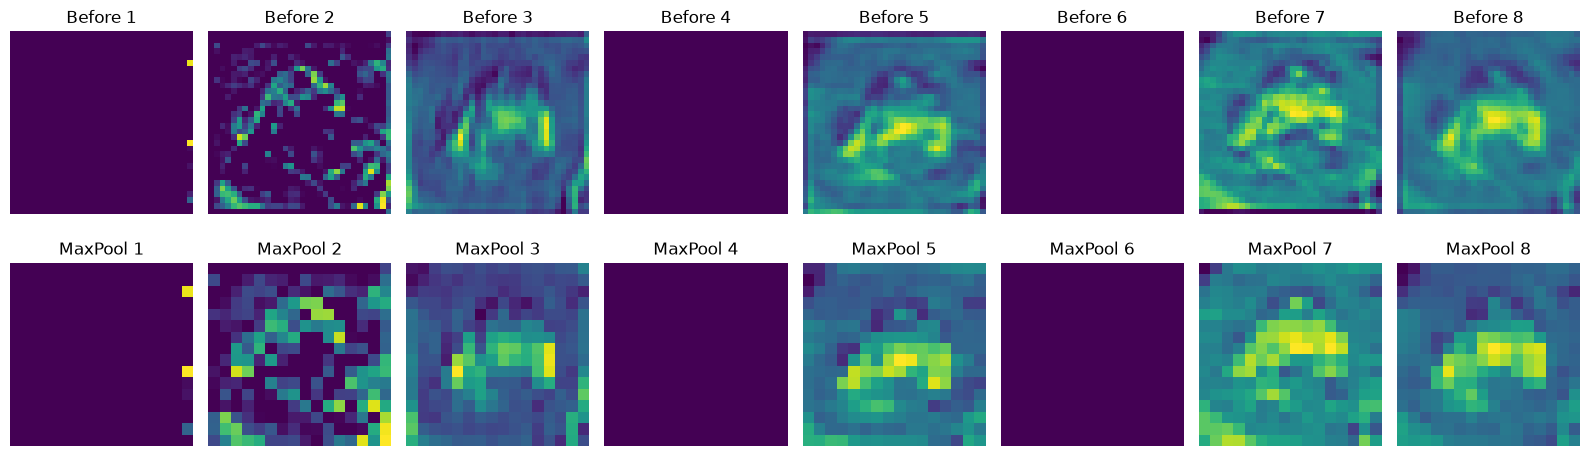

In [10]:
max_pool_model = keras.Sequential([
    model_vis,
    layers.MaxPooling2D((2, 2))
])
avg_pool_model = keras.Sequential([
    model_vis,
    layers.AveragePooling2D((2, 2))
])
max_maps = max_pool_model.predict(sample, verbose=0)[0]
avg_maps = avg_pool_model.predict(sample, verbose=0)[0]
print("Before pooling:", feature_maps.shape)
print("After max pooling:", max_maps.shape)
print("After average pooling:", avg_maps.shape)

fig, axes = plt.subplots(2, 8, figsize=(16, 5))
for i in range(8):
    axes[0, i].imshow(feature_maps[:, :, i], cmap="viridis")
    axes[0, i].set_title(f"Before {i+1}")
    axes[1, i].imshow(max_maps[:, :, i], cmap="viridis")
    axes[1, i].set_title(f"MaxPool {i+1}")
    axes[0, i].axis("off"); axes[1, i].axis("off")
plt.tight_layout(); plt.show()

In [11]:
flatten_model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(16, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(2, 2),
    layers.Flatten()
])
print("Tensor before Flatten:", (None, 16, 16, 16))
print("Tensor after Flatten :", flatten_model(sample).shape)

Tensor before Flatten: (None, 16, 16, 16)
Tensor after Flatten : (1, 4096)


In [12]:
lenet5 = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(6, (5, 5), activation="tanh"),
    layers.AveragePooling2D((2, 2)),
    layers.Conv2D(16, (5, 5), activation="tanh"),
    layers.AveragePooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(120, activation="tanh"),
    layers.Dense(84, activation="tanh"),
    layers.Dense(10, activation="softmax")
], name="LeNet5_CIFAR10")
lenet5.summary()
print("Conv1 params (manual):", (5*5*3 + 1) * 6)
print("Dense 120 params (manual):", 400*120 + 120)

Model: "LeNet5_CIFAR10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 6)      │           456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 14, 14, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_2             │ (None, 5, 5, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 62,006 (242.21 KB)

 Trainable params: 62,006 (242.21 KB)

 Non-trainable params: 0 (0.00 B)

Conv1 params (manual): 456
Dense 120 params (manual): 48120


In [13]:
def build_custom_cnn():
    return keras.Sequential([
        keras.Input(shape=(32, 32, 3)),
        layers.Conv2D(32, 3, activation="relu", padding="same"),
        layers.Conv2D(32, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(2, 2),
        layers.Conv2D(64, 3, activation="relu", padding="same"),
        layers.Conv2D(64, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(2, 2),
        layers.Conv2D(128, 3, activation="relu", padding="same"),
        layers.GlobalAveragePooling2D(),
        layers.Dense(256, activation="relu"),
        layers.Dense(10, activation="softmax")
    ], name="Custom_CNN")

model_cnn = build_custom_cnn()
model_cnn.summary()
assert model_cnn.count_params() < 2_000_000
print("Total parameters:", model_cnn.count_params())

Model: "Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 175,018 (683.66 KB)

 Trainable params: 175,018 (683.66 KB)

 Non-trainable params: 0 (0.00 B)

Total parameters: 175018


In [14]:
model_cnn.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
es = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True, verbose=1
)
rlrop = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=5, min_lr=1e-6, verbose=1
)
start_time = time.time()
history_cnn = model_cnn.fit(
    X_train, y_train_ohe,
    epochs=100, batch_size=64, validation_split=0.1,
    callbacks=[es, rlrop], verbose=1
)
print("Training minutes:", round((time.time()-start_time)/60, 2))

Epoch 1/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 91s 116ms/step - accuracy: 0.3348 - loss: 1.7577 - val_accuracy: 0.4608 - val_loss: 1.4594 - learning_rate: 0.0010
Epoch 2/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 84s 35ms/step - accuracy: 0.5089 - loss: 1.3301 - val_accuracy: 0.5520 - val_loss: 1.2125 - learning_rate: 0.0010
Epoch 3/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 27s 38ms/step - accuracy: 0.5892 - loss: 1.1354 - val_accuracy: 0.5958 - val_loss: 1.1064 - learning_rate: 0.0010
Epoch 4/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 80s 114ms/step - accuracy: 0.6379 - loss: 1.0042 - val_accuracy: 0.6726 - val_loss: 0.9288 - learning_rate: 0.0010
Epoch 5/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 78s 111ms/step - accuracy: 0.6749 - loss: 0.9107 - val_accuracy: 0.6526 - val_loss: 0.9823 - learning_rate: 0.0010
Epoch 6/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 93s 132ms/step - accuracy: 0.7020 - loss: 0.8346 - val_accuracy: 0.7208 - val_loss: 0.8031 - learning_rate: 0.0010
Epoch 7/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 81s 115ms/step - accuracy

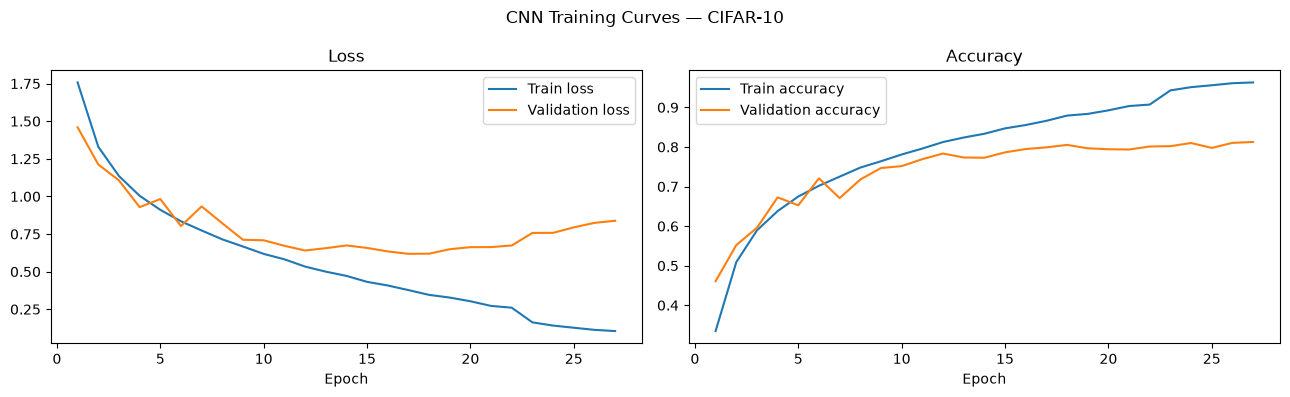

In [15]:
def plot_history(history, title, mark_finetune=None):
    h = history.history
    epochs = np.arange(1, len(h["loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(epochs, h["loss"], label="Train loss")
    ax[0].plot(epochs, h["val_loss"], label="Validation loss")
    ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
    ax[1].plot(epochs, h["accuracy"], label="Train accuracy")
    ax[1].plot(epochs, h["val_accuracy"], label="Validation accuracy")
    ax[1].set_title("Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
    if mark_finetune is not None:
        for a in ax: a.axvline(mark_finetune, color="red", linestyle="--", label="Fine-tuning start")
    fig.suptitle(title); plt.tight_layout(); plt.show()

plot_history(history_cnn, "CNN Training Curves — CIFAR-10")

Scratch CNN test accuracy: 0.7922


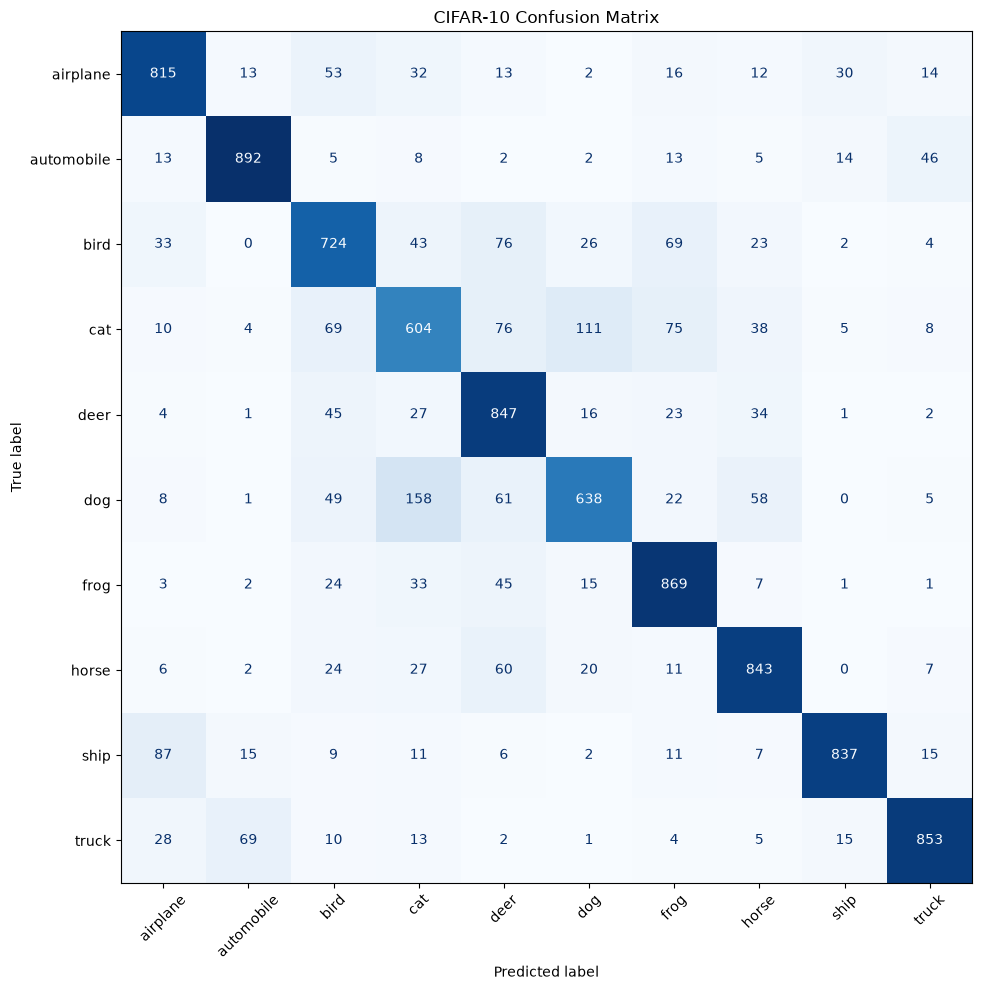

              precision    recall  f1-score   support

    airplane       0.81      0.81      0.81      1000
  automobile       0.89      0.89      0.89      1000
        bird       0.72      0.72      0.72      1000
         cat       0.63      0.60      0.62      1000
        deer       0.71      0.85      0.77      1000
         dog       0.77      0.64      0.70      1000
        frog       0.78      0.87      0.82      1000
       horse       0.82      0.84      0.83      1000
        ship       0.92      0.84      0.88      1000
       truck       0.89      0.85      0.87      1000

    accuracy                           0.79     10000
   macro avg       0.79      0.79      0.79     10000
weighted avg       0.79      0.79      0.79     10000

Saved tested scratch CNN to cnn_scratch_cifar10.keras


In [16]:
test_loss_cnn, test_acc_cnn = model_cnn.evaluate(X_test, y_test_ohe, verbose=0)
print(f"Scratch CNN test accuracy: {test_acc_cnn:.4f}")
probs = model_cnn.predict(X_test, batch_size=128, verbose=0)
y_pred = np.argmax(probs, axis=1)
y_true = y_test.flatten()
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES)
fig, ax = plt.subplots(figsize=(10, 10))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
plt.title("CIFAR-10 Confusion Matrix")
plt.tight_layout(); plt.show()
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

model_cnn.save(CNN_MODEL_PATH)
best_model = model_cnn
print(f"Saved tested scratch CNN to {CNN_MODEL_PATH}")

In [17]:
confusions = []
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if i != j:
            confusions.append((cm[i, j], CLASS_NAMES[i], CLASS_NAMES[j]))
print("Top 3 directed confusions (true -> predicted):")
for count, true_name, pred_name in sorted(confusions, reverse=True)[:3]:
    print(f"{true_name} -> {pred_name}: {count}")

Top 3 directed confusions (true -> predicted):
dog -> cat: 158
cat -> dog: 111
ship -> airplane: 87


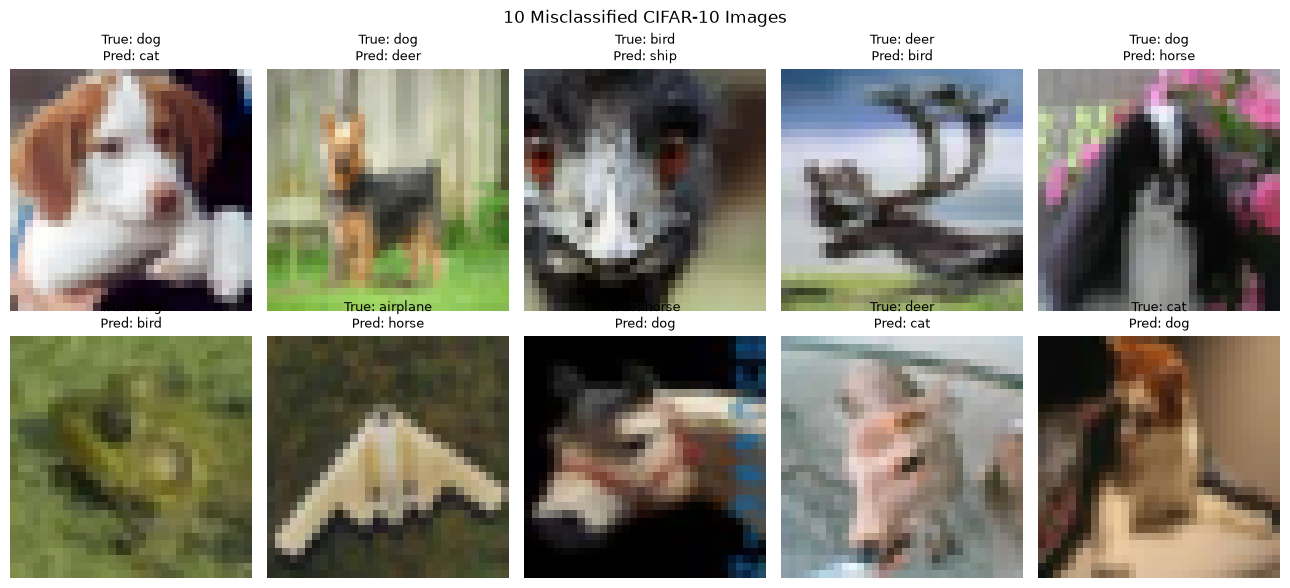

In [18]:
wrong = np.where(y_pred != y_true)[0][:10]
fig, axes = plt.subplots(2, 5, figsize=(13, 6))
for ax, idx in zip(axes.flat, wrong):
    ax.imshow(X_test_raw[idx])
    ax.set_title(f"True: {CLASS_NAMES[y_true[idx]]}\nPred: {CLASS_NAMES[y_pred[idx]]}", fontsize=9)
    ax.axis("off")
plt.suptitle("10 Misclassified CIFAR-10 Images")
plt.tight_layout(); plt.show()

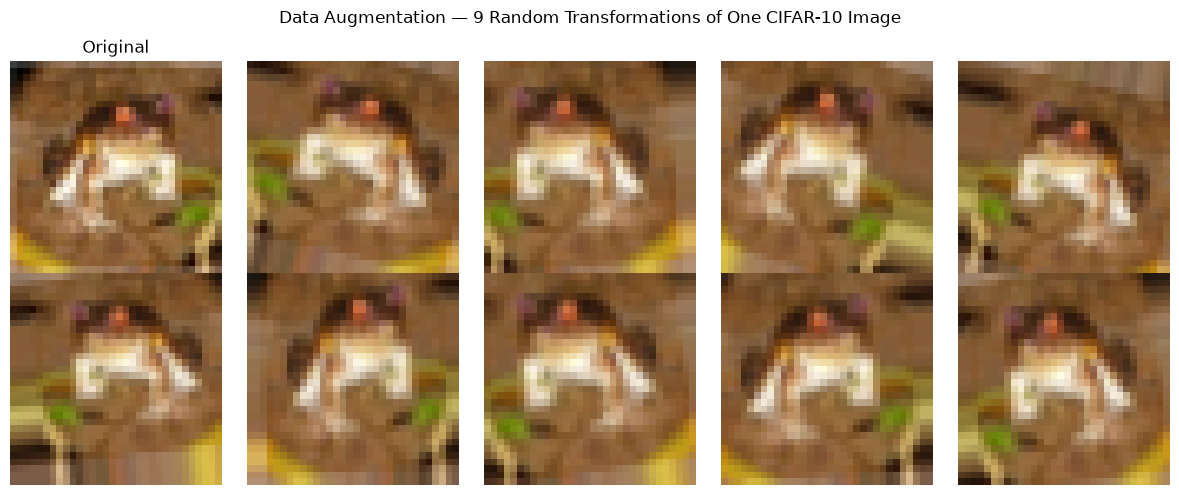

In [19]:
datagen = keras.preprocessing.image.ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1,
    fill_mode="nearest"
)
datagen.fit(X_train)
img = X_train[0]
aug_iter = datagen.flow(img[np.newaxis, ...], batch_size=1, shuffle=False)
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
axes[0, 0].imshow(img); axes[0, 0].set_title("Original"); axes[0, 0].axis("off")
for ax in axes.flat[1:]:
    aug_img = next(aug_iter)[0]
    ax.imshow(np.clip(aug_img, 0, 1)); ax.axis("off")
fig.suptitle("Data Augmentation — 9 Random Transformations of One CIFAR-10 Image")
plt.tight_layout(); plt.show()

In [20]:
model_aug = build_custom_cnn()
model_aug.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
es_aug = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
rlrop_aug = keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-6)
history_aug = model_aug.fit(
    datagen.flow(X_train, y_train_ohe, batch_size=64),
    steps_per_epoch=len(X_train)//64,
    epochs=100,
    validation_data=(X_test, y_test_ohe),
    callbacks=[es_aug, rlrop_aug],
    verbose=1
)
test_loss_aug, test_acc_aug = model_aug.evaluate(X_test, y_test_ohe, verbose=0)
print("ImageDataGenerator test accuracy:", round(test_acc_aug, 4))

Epoch 1/100
781/781 ━━━━━━━━━━━━━━━━━━━━ 36s 43ms/step - accuracy: 0.3189 - loss: 1.7866 - val_accuracy: 0.4349 - val_loss: 1.5540 - learning_rate: 0.0010
Epoch 2/100
  1/781 ━━━━━━━━━━━━━━━━━━━━ 41s 53ms/step - accuracy: 0.4688 - loss: 1.4118

c:\Users\rajw1\AppData\Roaming\uv\python\cpython-3.11.15-windows-x86_64-none\Lib\site-packages\keras\src\trainers\epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


781/781 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.4688 - loss: 1.4118 - val_accuracy: 0.4482 - val_loss: 1.5014 - learning_rate: 0.0010
Epoch 3/100
781/781 ━━━━━━━━━━━━━━━━━━━━ 32s 41ms/step - accuracy: 0.4975 - loss: 1.3726 - val_accuracy: 0.5435 - val_loss: 1.2367 - learning_rate: 0.0010
Epoch 4/100
781/781 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.5938 - loss: 1.1226 - val_accuracy: 0.5452 - val_loss: 1.2571 - learning_rate: 0.0010
Epoch 5/100
781/781 ━━━━━━━━━━━━━━━━━━━━ 32s 41ms/step - accuracy: 0.5702 - loss: 1.1916 - val_accuracy: 0.5991 - val_loss: 1.1233 - learning_rate: 0.0010
Epoch 6/100
781/781 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.5625 - loss: 1.0483 - val_accuracy: 0.6038 - val_loss: 1.1070 - learning_rate: 0.0010
Epoch 7/100
781/781 ━━━━━━━━━━━━━━━━━━━━ 32s 40ms/step - accuracy: 0.6133 - loss: 1.0807 - val_accuracy: 0.6294 - val_loss: 1.0385 - learning_rate: 0.0010
Epoch 8/100
781/781 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.5938 - loss: 1.0016 -

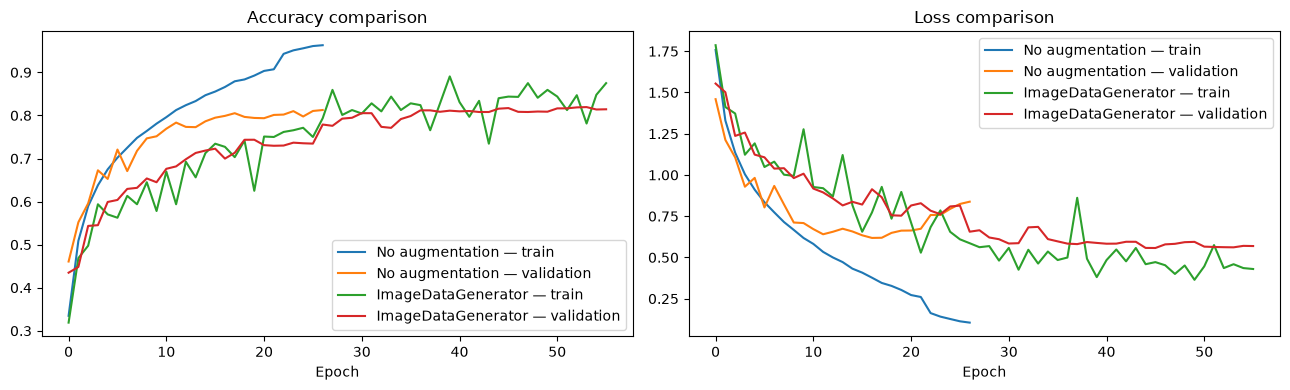

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(history_cnn.history["accuracy"], label="No augmentation — train")
ax[0].plot(history_cnn.history["val_accuracy"], label="No augmentation — validation")
ax[0].plot(history_aug.history["accuracy"], label="ImageDataGenerator — train")
ax[0].plot(history_aug.history["val_accuracy"], label="ImageDataGenerator — validation")
ax[0].set_title("Accuracy comparison"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(history_cnn.history["loss"], label="No augmentation — train")
ax[1].plot(history_cnn.history["val_loss"], label="No augmentation — validation")
ax[1].plot(history_aug.history["loss"], label="ImageDataGenerator — train")
ax[1].plot(history_aug.history["val_loss"], label="ImageDataGenerator — validation")
ax[1].set_title("Loss comparison"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

In [22]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1)
], name="data_augmentation")

def build_cnn_with_keras_augmentation():
    inputs = keras.Input(shape=(32, 32, 3))
    x = data_augmentation(inputs)
    x = layers.Conv2D(32, 3, activation="relu", padding="same")(x)
    x = layers.Conv2D(32, 3, activation="relu", padding="same")(x)
    x = layers.MaxPooling2D(2, 2)(x)
    x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
    x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
    x = layers.MaxPooling2D(2, 2)(x)
    x = layers.Conv2D(128, 3, activation="relu", padding="same")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="CNN_Keras_Augmentation")

model_keras_aug = build_cnn_with_keras_augmentation()
model_keras_aug.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
history_keras_aug = model_keras_aug.fit(
    X_train, y_train_ohe, epochs=100, batch_size=64, validation_split=0.1,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-6)
    ], verbose=1
)
test_loss_keras_aug, test_acc_keras_aug = model_keras_aug.evaluate(X_test, y_test_ohe, verbose=0)
print("Keras augmentation layers test accuracy:", round(test_acc_keras_aug, 4))

Epoch 1/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 31s 39ms/step - accuracy: 0.2850 - loss: 1.8820 - val_accuracy: 0.4036 - val_loss: 1.5918 - learning_rate: 0.0010
Epoch 2/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 27s 38ms/step - accuracy: 0.4258 - loss: 1.5623 - val_accuracy: 0.3840 - val_loss: 1.7500 - learning_rate: 0.0010
Epoch 3/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 28s 40ms/step - accuracy: 0.4811 - loss: 1.4138 - val_accuracy: 0.5378 - val_loss: 1.3070 - learning_rate: 0.0010
Epoch 4/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 45s 64ms/step - accuracy: 0.5252 - loss: 1.3113 - val_accuracy: 0.5258 - val_loss: 1.3870 - learning_rate: 0.0010
Epoch 5/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 130s 133ms/step - accuracy: 0.5547 - loss: 1.2322 - val_accuracy: 0.5448 - val_loss: 1.3496 - learning_rate: 0.0010
Epoch 6/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 101s 143ms/step - accuracy: 0.5788 - loss: 1.1756 - val_accuracy: 0.6050 - val_loss: 1.1765 - learning_rate: 0.0010
Epoch 7/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 102s 144ms/step - accurac

In [23]:
X_train_r = tf.image.resize(X_train, (96, 96)).numpy()
X_test_r = tf.image.resize(X_test, (96, 96)).numpy()
print("Resized train:", X_train_r.shape)
print("Resized test :", X_test_r.shape)

base_model = keras.applications.MobileNetV2(
    input_shape=(96, 96, 3), include_top=False, weights="imagenet"
)
base_model.trainable = False

inputs = keras.Input(shape=(96, 96, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
outputs = layers.Dense(10, activation="softmax")(x)
model_fe = keras.Model(inputs, outputs, name="MobileNetV2_Feature_Extraction")
model_fe.summary()
print("Total params:", model_fe.count_params())
print("Trainable params:", sum(np.prod(v.shape) for v in model_fe.trainable_weights))
print("Non-trainable params:", sum(np.prod(v.shape) for v in model_fe.non_trainable_weights))

Resized train: (50000, 96, 96, 3)
Resized test : (10000, 96, 96, 3)


Model: "MobileNetV2_Feature_Extraction"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_14 (InputLayer)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Total params: 2423242
Trainable params: 165258
Non-trainable params: 2257984


In [24]:
model_fe.compile(
    optimizer=keras.optimizers.Adam(0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
history_fe = model_fe.fit(
    X_train_r, y_train_ohe, epochs=20, batch_size=64,
    validation_split=0.1, verbose=1
)
test_loss_fe, test_acc_fe = model_fe.evaluate(X_test_r, y_test_ohe, verbose=0)
print("MobileNetV2 feature extraction test accuracy:", round(test_acc_fe, 4))

Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 131s 176ms/step - accuracy: 0.7481 - loss: 0.7234 - val_accuracy: 0.7834 - val_loss: 0.6113
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 143s 203ms/step - accuracy: 0.8057 - loss: 0.5553 - val_accuracy: 0.7958 - val_loss: 0.5800
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 184s 262ms/step - accuracy: 0.8252 - loss: 0.4951 - val_accuracy: 0.7998 - val_loss: 0.5807
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 217s 308ms/step - accuracy: 0.8400 - loss: 0.4510 - val_accuracy: 0.7966 - val_loss: 0.5880
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 230s 327ms/step - accuracy: 0.8544 - loss: 0.4088 - val_accuracy: 0.8122 - val_loss: 0.5590
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 223s 317ms/step - accuracy: 0.8670 - loss: 0.3717 - val_accuracy: 0.8058 - val_loss: 0.5774
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 185s 263ms/step - accuracy: 0.8793 - loss: 0.3386 - val_accuracy: 0.7940 - val_loss: 0.6323
Epoch 8/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 142s 201ms/step - accuracy: 0.8899 -

In [25]:
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False

model_fe.compile(
    optimizer=keras.optimizers.Adam(1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
history_ft = model_fe.fit(
    X_train_r, y_train_ohe, epochs=10, batch_size=32,
    validation_split=0.1, verbose=1
)
test_loss_ft, test_acc_ft = model_fe.evaluate(X_test_r, y_test_ohe, verbose=0)
print("MobileNetV2 fine-tuned test accuracy:", round(test_acc_ft, 4))

Epoch 1/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 449s 291ms/step - accuracy: 0.6922 - loss: 3.0603 - val_accuracy: 0.7782 - val_loss: 1.6376
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 225s 160ms/step - accuracy: 0.7685 - loss: 1.6609 - val_accuracy: 0.7760 - val_loss: 1.6214
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 335s 238ms/step - accuracy: 0.8009 - loss: 1.1751 - val_accuracy: 0.7816 - val_loss: 1.4469
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 363s 258ms/step - accuracy: 0.8255 - loss: 0.8670 - val_accuracy: 0.7872 - val_loss: 1.2955
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 337s 240ms/step - accuracy: 0.8406 - loss: 0.6811 - val_accuracy: 0.7934 - val_loss: 1.1665
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 316s 224ms/step - accuracy: 0.8596 - loss: 0.5453 - val_accuracy: 0.8004 - val_loss: 1.0829
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 297s 211ms/step - accuracy: 0.8746 - loss: 0.4514 - val_accuracy: 0.8050 - val_loss: 1.0217
Epoch 8/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 298s 212ms/step - ac

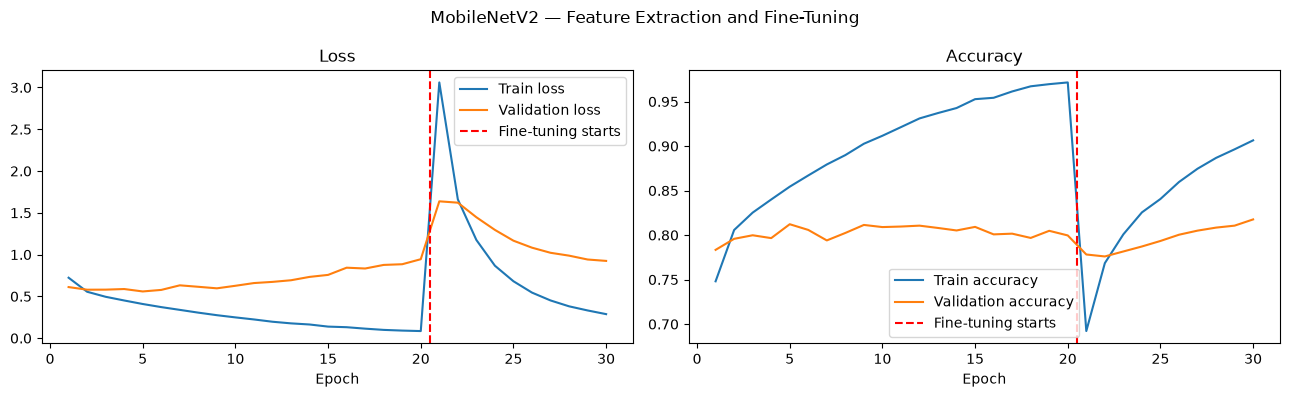

In [26]:
combined_loss = history_fe.history["loss"] + history_ft.history["loss"]
combined_val_loss = history_fe.history["val_loss"] + history_ft.history["val_loss"]
combined_acc = history_fe.history["accuracy"] + history_ft.history["accuracy"]
combined_val_acc = history_fe.history["val_accuracy"] + history_ft.history["val_accuracy"]
ft_start_epoch = len(history_fe.history["loss"]) + 0.5
epochs = np.arange(1, len(combined_loss) + 1)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(epochs, combined_loss, label="Train loss")
ax[0].plot(epochs, combined_val_loss, label="Validation loss")
ax[1].plot(epochs, combined_acc, label="Train accuracy")
ax[1].plot(epochs, combined_val_acc, label="Validation accuracy")
for a in ax:
    a.axvline(ft_start_epoch, color="red", linestyle="--", label="Fine-tuning starts")
    a.legend()
ax[0].set_title("Loss"); ax[1].set_title("Accuracy")
for a in ax: a.set_xlabel("Epoch")
plt.suptitle("MobileNetV2 — Feature Extraction and Fine-Tuning")
plt.tight_layout(); plt.show()

In [27]:
lenet5.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model_cnn.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model_aug.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model_keras_aug.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model_fe.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [29]:
_, lenet_acc = lenet5.evaluate(X_test, y_test_ohe, verbose=0)
_, scratch_acc = model_cnn.evaluate(X_test, y_test_ohe, verbose=0)
_, idg_acc = model_aug.evaluate(X_test, y_test_ohe, verbose=0)
_, keras_aug_acc = model_keras_aug.evaluate(X_test, y_test_ohe, verbose=0)
_, fe_acc = model_fe.evaluate(X_test_r, y_test_ohe, verbose=0)

results = pd.DataFrame([
    ["LeNet-5", "LeNet-5", "No", "No", lenet_acc, lenet5.count_params()],
    ["CNN Scratch No Aug", "Custom CNN", "No", "No", scratch_acc, model_cnn.count_params()],
    ["CNN Scratch + Aug", "Custom CNN", "ImageDataGenerator", "No", idg_acc, model_aug.count_params()],
    ["CNN + Keras Aug Layers", "Custom CNN", "Keras preprocessing", "No", keras_aug_acc, model_keras_aug.count_params()],
    ["MobileNetV2 Feature Extraction", "MobileNetV2", "No", "Yes — frozen base", fe_acc, model_fe.count_params()],
    ["MobileNetV2 Fine-Tuned", "MobileNetV2", "No", "Yes — top 30 layers", test_acc_ft, model_fe.count_params()]
], columns=["Model", "Architecture", "Augmentation", "Transfer Learning", "Test Accuracy", "Parameters"])
results_display = results.copy()
results_display["Test Accuracy"] = results_display["Test Accuracy"].map("{:.4f}".format)
results_display["Parameters"] = results_display["Parameters"].map("{:,}".format)
display(results_display)

,Model,Architecture,Augmentation,Transfer Learning,Test Accuracy,Parameters
0,LeNet-5,LeNet-5,No,No,0.1108,"62,006"
1,CNN Scratch No Aug,Custom CNN,No,No,0.7922,"175,018"
2,CNN Scratch + Aug,Custom CNN,ImageDataGenerator,No,0.8171,"175,018"
3,CNN + Keras Aug Layers,Custom CNN,Keras preprocessing,No,0.7897,"175,018"
4,MobileNetV2 Feature Extraction,MobileNetV2,No,Yes — frozen base,0.8100,"2,423,242"
5,MobileNetV2 Fine-Tuned,MobileNetV2,No,Yes — top 30 layers,0.8100,"2,423,242"


In [30]:
res_inputs = keras.Input(shape=(32, 32, 64))
shortcut = layers.Conv2D(64, (1, 1), padding="same")(res_inputs)
x = layers.Conv2D(64, (3, 3), padding="same", activation="relu")(res_inputs)
x = layers.Conv2D(64, (3, 3), padding="same")(x)
x = layers.Add()([x, shortcut])
res_outputs = layers.Activation("relu")(x)
residual_block_model = keras.Model(res_inputs, res_outputs, name="Residual_Block_Demo")
residual_block_model.summary()

Model: "Residual_Block_Demo"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_15      │ (None, 32, 32,    │          0 │ -                 │
│ (InputLayer)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_24 (Conv2D)  │ (None, 32, 32,    │     36,928 │ input_layer_15[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_25 (Conv2D)  │ (None, 32, 32,    │     36,928 │ conv2d_24[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_23 (Conv2D)  │ (None, 32, 32,    │      4,160 │ input_layer_15[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32, 32,    │          0 │ conv2d_25[0][0],  │
│                     │ 64)               │            │ conv2d_23[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 32, 32,    │          0 │ add[0][0]         │
│ (Activation)        │ 64)               │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 78,016 (304.75 KB)

 Trainable params: 78,016 (304.75 KB)

 Non-trainable params: 0 (0.00 B)

In [31]:
os.makedirs("plots", exist_ok=True)
results.to_csv("model_comparison.csv", index=False)
results.to_csv("plots/model_comparison.csv", index=False)

model_map = {
    "LeNet-5": lenet5,
    "CNN Scratch No Aug": model_cnn,
    "CNN Scratch + Aug": model_aug,
    "CNN + Keras Aug Layers": model_keras_aug,
    "MobileNetV2 Feature Extraction": model_fe,
    "MobileNetV2 Fine-Tuned": model_fe
}
best_row = results.loc[results["Test Accuracy"].idxmax()]
best_model = model_map[best_row["Model"]]
best_model.save(MODEL_PATH)
print("Saved best model:", best_row["Model"])
print("Saved accuracy:", best_row["Test Accuracy"])
print("Model file:", MODEL_PATH)

Saved best model: CNN Scratch + Aug
Saved accuracy: 0.8170999884605408
Model file: best_cifar10_model.keras
